# Projeto AM 2026-2 — Versão final

**Disciplina:** Aprendizagem de Máquina — Prof. Francisco de A. T. de Carvalho (CIn/UFPE)
**Base:** Spambase (UCI, id 94) — 4601 e-mails, 57 atributos numéricos, classe `is_spam`.

Este notebook responde às duas questões do projeto:

1. **Questão 1** — agrupamento de objetos e variáveis com o **double k-means**
   (100 execuções para cada par $(K,H)$, $K\in\{2,3,4\}$, $H\in\{1,\dots,K\}$), escolha de
   $K^*$ pela silhueta, índice de Rand corrigido, matriz de protótipos $G$, matriz de confusão e
   curva da função objetivo.
2. **Questão 2** — comparação de 5 classificadores (bayesiano gaussiano, bayesiano k-NN,
   bayesiano Parzen, regressão logística e voto majoritário) em duas versões da base
   (classe original e classe = clusters de $K^*$), com validação cruzada estratificada
   30×10-folds, ajuste de hiper-parâmetros por 5-folds internos, estimativas pontuais e
   intervalos de confiança, testes de Friedman e Nemenyi e curvas de aprendizagem.

O código usa **PyTorch na GPU** (quando disponível) para o double k-means (as 100
inicializações são executadas em paralelo, em lote), para o k-NN, a janela de Parzen e o
bayesiano gaussiano. A regressão logística usa o `scikit-learn` (CPU, em paralelo).

In [1]:
import os, time, json, warnings, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
import scipy.stats as st
import scikit_posthocs as sp
from joblib import Parallel, delayed
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (silhouette_score, adjusted_rand_score, confusion_matrix,
                             precision_score, recall_score, f1_score)
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float64            # a A100 tem bom desempenho em FP64
SEED = 2026
N_JOBS = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count() or 4))
QUICK = os.environ.get("AM_QUICK", "0") == "1"   # modo de teste rápido (não usar no relatório)

OUT = "resultados_versao_final"
os.makedirs(OUT, exist_ok=True)

print("Python", platform.python_version(), "| torch", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("CPUs para a regressão logística:", N_JOBS, "| modo rápido:", QUICK)
T0_GLOBAL = time.time()

Python 3.11.18 | torch 2.15.0+cu132 | device: cuda
GPU: NVIDIA A100 80GB PCIe MIG 1g.10gb
CPUs para a regressão logística: 16 | modo rápido: False


## 1. Descrição dos dados

A Spambase contém 4601 mensagens de e-mail, 1813 rotuladas como spam (39,4%) e 2788 como
não-spam (60,6%). Os 57 atributos são contínuos e não há valores ausentes:

* 48 atributos `word_freq_*`: percentual de palavras do e-mail iguais a uma palavra dada (0–100);
* 6 atributos `char_freq_*`: percentual de caracteres iguais a `; ( [ ! $ #`;
* 3 atributos `capital_run_length_*`: média, maior e total das sequências de letras maiúsculas.

Os atributos têm escalas muito diferentes (os `capital_run_length_*` chegam a milhares) e
distribuições muito assimétricas, com muitos zeros. Por isso os dados são **padronizados
(z-score)**: na Questão 1 sobre toda a base (agrupamento é não supervisionado) e, na Questão 2,
com média e desvio estimados **apenas no conjunto de treinamento** de cada fold.

In [2]:
COLUNAS = [
    "word_freq_make", "word_freq_address", "word_freq_all", "word_freq_3d", "word_freq_our",
    "word_freq_over", "word_freq_remove", "word_freq_internet", "word_freq_order", "word_freq_mail",
    "word_freq_receive", "word_freq_will", "word_freq_people", "word_freq_report", "word_freq_addresses",
    "word_freq_free", "word_freq_business", "word_freq_email", "word_freq_you", "word_freq_credit",
    "word_freq_your", "word_freq_font", "word_freq_000", "word_freq_money", "word_freq_hp",
    "word_freq_hpl", "word_freq_george", "word_freq_650", "word_freq_lab", "word_freq_labs",
    "word_freq_telnet", "word_freq_857", "word_freq_data", "word_freq_415", "word_freq_85",
    "word_freq_technology", "word_freq_1999", "word_freq_parts", "word_freq_pm", "word_freq_direct",
    "word_freq_cs", "word_freq_meeting", "word_freq_original", "word_freq_project", "word_freq_re",
    "word_freq_edu", "word_freq_table", "word_freq_conference", "char_freq_;", "char_freq_(",
    "char_freq_[", "char_freq_!", "char_freq_$", "char_freq_#", "capital_run_length_average",
    "capital_run_length_longest", "capital_run_length_total", "is_spam"]

df = pd.read_csv("spambase.data", header=None, names=COLUNAS)
X_raw = df.drop(columns="is_spam").values.astype(np.float64)
y_orig = df["is_spam"].values.astype(np.int64)
N, P = X_raw.shape
print(f"N = {N} objetos, P = {P} variáveis, valores ausentes: {int(df.isna().sum().sum())}")
print(df["is_spam"].value_counts().rename({0: "não-spam (0)", 1: "spam (1)"}).to_frame("n")
      .assign(perc=lambda t: (100 * t.n / N).round(1)))
desc = df.drop(columns="is_spam").describe().T[["mean", "std", "min", "50%", "max"]]
desc["% zeros"] = (100 * (df.drop(columns="is_spam") == 0).mean()).round(1)
desc.round(3)

N = 4601 objetos, P = 57 variáveis, valores ausentes: 0
                 n  perc
is_spam                 
não-spam (0)  2788  60.6
spam (1)      1813  39.4


,mean,std,min,50%,max,% zeros
word_freq_make,0.105,0.305,0.0,0.000,4.540,77.1
word_freq_address,0.213,1.291,0.0,0.000,14.280,80.5
word_freq_all,0.281,0.504,0.0,0.000,5.100,59.0
word_freq_3d,0.065,1.395,0.0,0.000,42.810,99.0
word_freq_our,0.312,0.673,0.0,0.000,10.000,62.0
word_freq_over,0.096,0.274,0.0,0.000,5.880,78.3
word_freq_remove,0.114,0.391,0.0,0.000,7.270,82.5
word_freq_internet,0.105,0.401,0.0,0.000,11.110,82.1
word_freq_order,0.090,0.279,0.0,0.000,5.260,83.2
word_freq_mail,0.239,0.645,0.0,0.000,18.180,71.7


## 2. Questão 1 — Double k-means

**Função objetivo** (heterogeneidade total dos $K\times H$ blocos):
$$W(G,U,V)=\sum_{k=1}^{K}\sum_{h=1}^{H}\sum_{i=1}^{N}\sum_{j=1}^{P}u_{ik}\,v_{jh}\,(x_{ij}-g_{kh})^2 .$$

**Algoritmo** (como nos slides): a partir de partições aleatórias $U^{(0)},V^{(0)}$, repete

1. *Passo 1* — protótipos ótimos com $U,V$ fixos: $g_{kh}=\frac{1}{n_k n_h}\sum_{i\in P_k}\sum_{j\in Q_h}x_{ij}$;
2. *Passo 2* — com $G,V$ fixos, cada objeto vai para o grupo $k$ que minimiza $\sum_h\sum_{j\in Q_h}(x_{ij}-g_{kh})^2$;
3. *Passo 3* — com $G,U$ fixos, cada variável vai para o grupo $h$ que minimiza $\sum_k\sum_{i\in P_k}(x_{ij}-g_{kh})^2$;

enquanto houver transferência de objetos ou variáveis. Se um grupo ficar vazio, ele recebe o
elemento mais distante do protótipo do próprio grupo (de um grupo com mais de um elemento).

**Implementação na GPU.** As distâncias são expandidas algebricamente, por exemplo
$\sum_h\sum_{j\in Q_h}(x_{ij}-g_{kh})^2=\|x_i\|^2-2\sum_h g_{kh}(XV)_{ih}+\sum_h n_h g_{kh}^2$,
o que transforma cada passo em produtos matriciais. As **100 inicializações** de cada par
$(K,H)$ rodam juntas, como um lote de tensores; cada execução para quando não há mais
transferências. Para cada par fica a execução com **menor $W$**.

In [3]:
def _one_hot(lab, C):
    return F.one_hot(lab, C).to(DTYPE)

def _corrige_vazios(lab, custo, C):
    # lab: (R, M) rótulos; custo: (R, M, C). Grupo vazio recebe o elemento mais distante
    # do protótipo do próprio grupo, escolhido entre grupos com mais de um elemento.
    vazios = (_one_hot(lab, C).sum(1) == 0).nonzero().tolist()
    for r, c in vazios:
        cont = torch.bincount(lab[r], minlength=C)
        proprio = custo[r].gather(1, lab[r][:, None]).squeeze(1).clone()
        proprio[cont[lab[r]] <= 1] = -float("inf")
        lab[r, int(proprio.argmax())] = c
    return lab

def _estat_blocos(X, u, v, K, H):
    U, V = _one_hot(u, K), _one_hot(v, H)
    UX = torch.einsum("rnk,np->rkp", U, X)     # somas por grupo de objetos   (R, K, P)
    S = UX @ V                                  # somas por bloco               (R, K, H)
    return U, V, UX, S, U.sum(1), V.sum(1)

def _objetivo(S, G, nk, nh, total):
    # W = sum x^2 - 2 sum_kh g_kh S_kh + sum_kh n_k n_h g_kh^2
    return total - 2 * (G * S).sum((1, 2)) + (nk[:, :, None] * nh[:, None, :] * G ** 2).sum((1, 2))

def double_kmeans(X, K, H, n_exec=100, max_iter=500, seed=0):
    # Executa n_exec inicializações do double k-means em paralelo e devolve a melhor (menor W).
    Nn, Pp = X.shape
    R = n_exec
    gen = torch.Generator(device=X.device).manual_seed(seed)
    u = torch.randint(0, K, (R, Nn), generator=gen, device=X.device)
    v = torch.randint(0, H, (R, Pp), generator=gen, device=X.device)
    u = _corrige_vazios(u, torch.rand(R, Nn, K, generator=gen, device=X.device, dtype=DTYPE), K)
    v = _corrige_vazios(v, torch.rand(R, Pp, H, generator=gen, device=X.device, dtype=DTYPE), H)

    total, quad_lin, quad_col = (X ** 2).sum(), (X ** 2).sum(1), (X ** 2).sum(0)
    _, _, _, S, nk, nh = _estat_blocos(X, u, v, K, H)
    G = S / (nk[:, :, None] * nh[:, None, :])
    historico = [_objetivo(S, G, nk, nh, total)]          # W na solução inicial
    ativo = torch.ones(R, dtype=torch.bool, device=X.device)
    n_iter = torch.zeros(R, dtype=torch.long, device=X.device)

    for it in range(1, max_iter + 1):
        # Passo 1: protótipos ótimos (U, V fixos)
        _, V, _, S, nk, nh = _estat_blocos(X, u, v, K, H)
        G = S / (nk[:, :, None] * nh[:, None, :])
        # Passo 2: partição dos objetos (G, V fixos)
        XV = torch.einsum("np,rph->rnh", X, V)
        Du = (quad_lin[None, :, None] - 2 * torch.einsum("rnh,rkh->rnk", XV, G)
              + torch.einsum("rh,rkh->rk", nh, G ** 2)[:, None, :])
        u_novo = _corrige_vazios(Du.argmin(2), Du, K)
        U = _one_hot(u_novo, K)
        nk = U.sum(1)
        UX = torch.einsum("rnk,np->rkp", U, X)
        # Passo 3: partição das variáveis (G, U fixos)
        Dv = (quad_col[None, :, None] - 2 * torch.einsum("rkp,rkh->rph", UX, G)
              + torch.einsum("rk,rkh->rh", nk, G ** 2)[:, None, :])
        v_novo = _corrige_vazios(Dv.argmin(2), Dv, H)

        mudou = (u_novo != u).any(1) | (v_novo != v).any(1)
        u, v = u_novo, v_novo
        V = _one_hot(v, H)
        W = _objetivo(UX @ V, G, nk, V.sum(1), total)
        historico.append(torch.where(ativo, W, historico[-1]))
        n_iter += ativo.long()
        ativo &= mudou
        if not ativo.any():
            break

    # protótipos e objetivo finais (ótimos para a partição final)
    _, _, _, S, nk, nh = _estat_blocos(X, u, v, K, H)
    G = S / (nk[:, :, None] * nh[:, None, :])
    W_final = _objetivo(S, G, nk, nh, total)
    hist = torch.stack(historico).cpu().numpy()          # (iterações+1, R)
    b = int(W_final.argmin())
    return dict(K=K, H=H, u=u[b].cpu().numpy(), v=v[b].cpu().numpy(), G=G[b].cpu().numpy(),
                W=float(W_final[b]), W_todas=W_final.cpu().numpy(),
                n_iter=int(n_iter[b]), historico=hist[: int(n_iter[b]) + 1, b],
                nao_convergiu=int(ativo.sum()))

In [4]:
X_q1 = StandardScaler().fit_transform(X_raw)          # z-score sobre toda a base
Xt_q1 = torch.as_tensor(X_q1, dtype=DTYPE, device=DEVICE)

N_EXEC = 10 if QUICK else 100
PARES = [(K, H) for K in (2, 3, 4) for H in range(1, K + 1)]
res_q1, linhas = {}, []
for i, (K, H) in enumerate(PARES):
    t = time.time()
    r = double_kmeans(Xt_q1, K, H, n_exec=N_EXEC, seed=SEED + 100 * K + H)
    r["sil"] = silhouette_score(X_q1, r["u"], metric="euclidean")
    res_q1[(K, H)] = r
    linhas.append(dict(K=K, H=H, W_melhor=r["W"], W_mediana=np.median(r["W_todas"]),
                       iter_melhor=r["n_iter"], silhueta=r["sil"],
                       tam_grupos=str(np.bincount(r["u"], minlength=K).tolist()),
                       nao_convergiram=r["nao_convergiu"], tempo_s=time.time() - t))
    print(f"(K={K}, H={H})  W* = {r['W']:.2f}  Sil = {r['sil']:.4f}  "
          f"grupos = {np.bincount(r['u'], minlength=K).tolist()}  ({time.time() - t:.1f} s)")

tab_q1 = pd.DataFrame(linhas)
tab_q1.to_csv(f"{OUT}/q1_pares_KH.csv", index=False)
tab_q1.round(4)

(K=2, H=1)  W* = 256513.75  Sil = 0.2961  grupos = [3583, 1018]  (2.1 s)


(K=2, H=2)  W* = 244486.70  Sil = 0.6596  grupos = [4567, 34]  (1.2 s)


(K=3, H=1)  W* = 254414.01  Sil = 0.2515  grupos = [1187, 3382, 32]  (1.0 s)


(K=3, H=2)  W* = 239373.66  Sil = 0.2454  grupos = [34, 3470, 1097]  (1.2 s)


(K=3, H=3)  W* = 234585.87  Sil = 0.1409  grupos = [34, 3373, 1194]  (1.5 s)


(K=4, H=1)  W* = 253278.68  Sil = 0.0484  grupos = [2242, 22, 697, 1640]  (0.9 s)


(K=4, H=2)  W* = 233358.70  Sil = 0.2428  grupos = [3275, 1049, 253, 24]  (1.3 s)


(K=4, H=3)  W* = 228516.44  Sil = 0.1620  grupos = [24, 3256, 1080, 241]  (1.3 s)


(K=4, H=4)  W* = 227086.08  Sil = 0.1697  grupos = [26, 1039, 3249, 287]  (1.3 s)


,K,H,W_melhor,W_mediana,iter_melhor,silhueta,tam_grupos,nao_convergiram,tempo_s
0,2,1,256513.7482,256513.7482,11,0.2961,"[3583, 1018]",0,2.0902
1,2,2,244486.6983,254103.3836,40,0.6596,"[4567, 34]",0,1.1803
2,3,1,254414.0129,254414.0129,40,0.2515,"[1187, 3382, 32]",0,0.9756
3,3,2,239373.6577,251463.0259,60,0.2454,"[34, 3470, 1097]",0,1.1773
4,3,3,234585.8664,234850.3095,34,0.1409,"[34, 3373, 1194]",0,1.4689
5,4,1,253278.6795,253278.6795,38,0.0484,"[2242, 22, 697, 1640]",0,0.9457
6,4,2,233358.7022,242159.2614,35,0.2428,"[3275, 1049, 253, 24]",0,1.2534
7,4,3,228516.4437,239325.1402,45,0.1620,"[24, 3256, 1080, 241]",0,1.2615
8,4,4,227086.0777,228799.0631,49,0.1697,"[26, 1039, 3249, 287]",0,1.2686


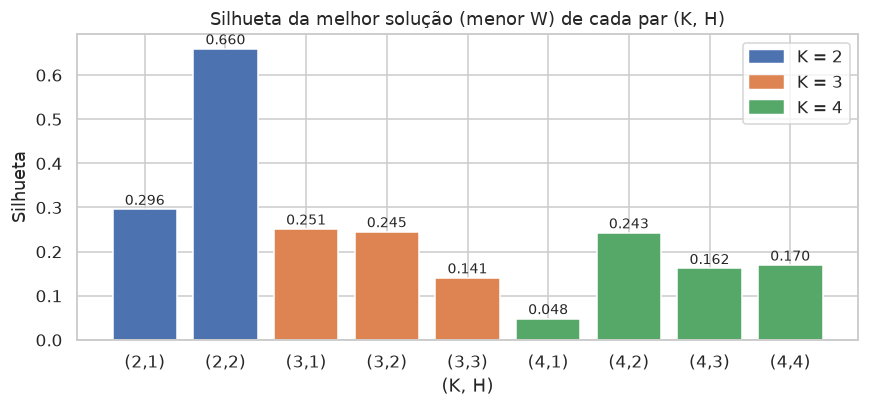

Par escolhido: (K, H) = (2, 2)  ->  K* = 2  (silhueta = 0.6596)
Índice de Rand corrigido (partição de K* vs classe a priori): ARI = -0.0049


In [5]:
rotulos = [f"({K},{H})" for K, H in PARES]
fig, ax = plt.subplots(figsize=(8, 3.8))
cores = {2: "#4C72B0", 3: "#DD8452", 4: "#55A868"}
ax.bar(rotulos, tab_q1.silhueta, color=[cores[K] for K, _ in PARES])
for x, s in enumerate(tab_q1.silhueta):
    ax.text(x, s + 0.01, f"{s:.3f}", ha="center", fontsize=9)
ax.set_xlabel("(K, H)"); ax.set_ylabel("Silhueta")
ax.set_title("Silhueta da melhor solução (menor W) de cada par (K, H)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f"K = {k}") for k, c in cores.items()], loc="upper right")
plt.tight_layout(); plt.savefig(f"{OUT}/q1_silhueta.png", dpi=200); plt.show()

i_best = int(tab_q1.silhueta.values.argmax())
K_STAR, H_STAR = PARES[i_best]
best = res_q1[(K_STAR, H_STAR)]
ari = adjusted_rand_score(y_orig, best["u"])
print(f"Par escolhido: (K, H) = ({K_STAR}, {H_STAR})  ->  K* = {K_STAR}  (silhueta = {best['sil']:.4f})")
print(f"Índice de Rand corrigido (partição de K* vs classe a priori): ARI = {ari:.4f}")

Matriz de protótipos G (dados padronizados):


,Q1 (n=46),Q2 (n=11)
P1 (n=4567),0.0011,-0.0511
P2 (n=34),-0.1444,6.8612


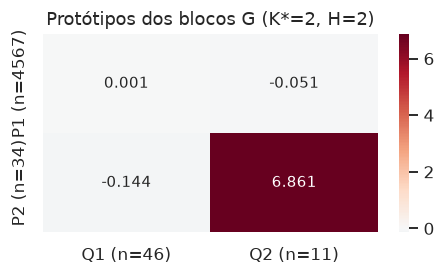

Grupo de variáveis Q1 (46 variáveis): word_freq_make, word_freq_address, word_freq_all, word_freq_3d, word_freq_our, word_freq_over, word_freq_remove, word_freq_internet, word_freq_order, word_freq_mail, word_freq_receive, word_freq_will, word_freq_people, word_freq_report, word_freq_addresses, word_freq_free, word_freq_business, word_freq_email, word_freq_you, word_freq_credit, word_freq_your, word_freq_font, word_freq_000, word_freq_money, word_freq_george, word_freq_data, word_freq_1999, word_freq_parts, word_freq_pm, word_freq_cs, word_freq_meeting, word_freq_original, word_freq_project, word_freq_re, word_freq_edu, word_freq_table, word_freq_conference, char_freq_;, char_freq_(, char_freq_[, char_freq_!, char_freq_$, char_freq_#, capital_run_length_average, capital_run_length_longest, capital_run_length_total
Grupo de variáveis Q2 (11 variáveis): word_freq_hp, word_freq_hpl, word_freq_650, word_freq_lab, word_freq_labs, word_freq_telnet, word_freq_857, word_freq_415, word_freq_85,

In [6]:
# i) Matriz de protótipos dos blocos G
G_df = pd.DataFrame(best["G"], index=[f"P{k+1} (n={n})" for k, n in enumerate(np.bincount(best['u'], minlength=K_STAR))],
                    columns=[f"Q{h+1} (n={n})" for h, n in enumerate(np.bincount(best['v'], minlength=H_STAR))])
print("Matriz de protótipos G (dados padronizados):")
display(G_df.round(4))
fig, ax = plt.subplots(figsize=(1.6 + 1.4 * H_STAR, 0.8 + 0.9 * K_STAR))
sns.heatmap(G_df, annot=True, fmt=".3f", cmap="RdBu_r", center=0, cbar=True, ax=ax)
ax.set_title(f"Protótipos dos blocos G (K*={K_STAR}, H={H_STAR})")
plt.tight_layout(); plt.savefig(f"{OUT}/q1_matriz_G.png", dpi=200); plt.show()

nomes_var = np.array(COLUNAS[:-1])
for h in range(H_STAR):
    print(f"Grupo de variáveis Q{h+1} ({(best['v'] == h).sum()} variáveis):", ", ".join(nomes_var[best["v"] == h]))

Classe a priori,não-spam,spam,Total
Cluster (double k-means),,,
P1,2754,1813,4567
P2,34,0,34
Total,2788,1813,4601


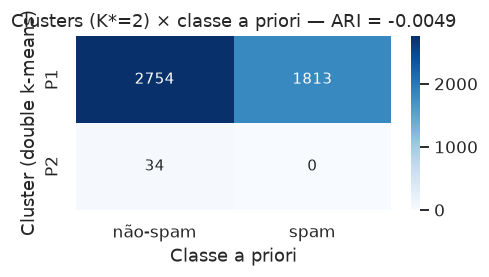

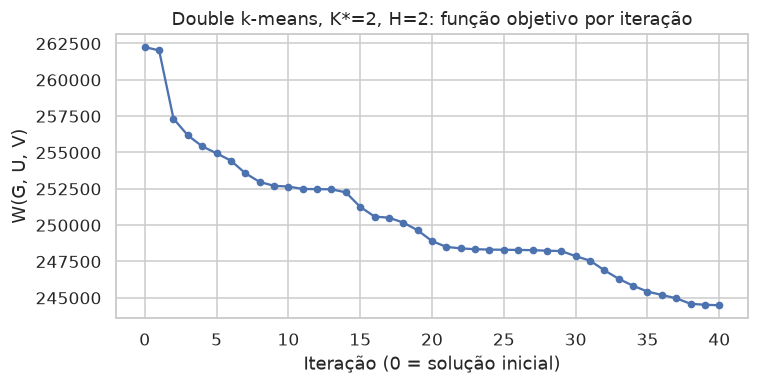

W por iteração: [262253.78, 262023.48, 257329.59, 256177.08, 255422.47, 254944.35, 254438.69, 253571.44, 252974.17, 252705.51, 252654.59, 252490.73, 252474.94, 252465.8, 252255.64, 251255.01, 250592.61, 250510.72, 250177.74, 249644.74, 248903.17, 248503.45, 248400.7, 248343.6, 248317.56, 248306.2, 248293.28, 248279.13, 248241.08, 248215.74, 247865.75, 247556.69, 246892.77, 246303.7, 245828.62, 245428.89, 245195.61, 244966.2, 244587.36, 244520.55, 244486.7]


In [7]:
# ii) Matriz de confusão: partição do double k-means vs classe a priori
cm = pd.crosstab(pd.Series(best["u"], name="Cluster (double k-means)").map(lambda k: f"P{k+1}"),
                 pd.Series(y_orig, name="Classe a priori").map({0: "não-spam", 1: "spam"}),
                 margins=True, margins_name="Total")
display(cm)
fig, ax = plt.subplots(figsize=(4.5, 1.2 + 0.7 * K_STAR))
sns.heatmap(cm.iloc[:-1, :-1], annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title(f"Clusters (K*={K_STAR}) × classe a priori — ARI = {ari:.4f}")
plt.tight_layout(); plt.savefig(f"{OUT}/q1_matriz_confusao.png", dpi=200); plt.show()

# iii) Função objetivo × iterações (melhor execução de K*)
hist = best["historico"]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(range(len(hist)), hist, "o-", ms=4)
ax.set_xlabel("Iteração (0 = solução inicial)"); ax.set_ylabel("W(G, U, V)")
ax.set_title(f"Double k-means, K*={K_STAR}, H={H_STAR}: função objetivo por iteração")
plt.tight_layout(); plt.savefig(f"{OUT}/q1_objetivo_iteracoes.png", dpi=200); plt.show()
print("W por iteração:", np.round(hist, 2).tolist())
assert np.all(np.diff(hist) <= 1e-6 * hist[0]), "a função objetivo deveria ser não crescente"

json.dump(dict(K_star=K_STAR, H_star=H_STAR, silhueta=best["sil"], ARI=ari, W=best["W"],
               G=best["G"].tolist(), grupos_variaveis={f"Q{h+1}": nomes_var[best['v'] == h].tolist() for h in range(H_STAR)},
               tamanhos_clusters=np.bincount(best["u"]).tolist(), historico_W=hist.tolist()),
          open(f"{OUT}/q1_resumo.json", "w"), indent=2, ensure_ascii=False)

### Comentário — Questão 1

* **Escolha de $K^*$.** A silhueta é máxima em $(K,H)=(2,2)$, com valor **0,660**, bem acima dos
  outros pares (todos ≤ 0,30). Logo **$K^*=2$**. A função objetivo da melhor execução cai de forma
  monótona, de 262 254 para 244 487, e converge em 40 iterações (sem transferências).
* **O que a partição representa.** Ela é muito desbalanceada: $P_1$ tem 4567 e-mails e $P_2$ só
  **34**. Os blocos de variáveis separam $Q_2$ (11 variáveis: `hp`, `hpl`, `650`, `lab`, `labs`,
  `telnet`, `857`, `415`, `85`, `technology`, `direct`) das outras 46 ($Q_1$). O protótipo
  $g_{P_2,Q_2}=6{,}86$ desvios-padrão contra $\approx 0$ nos demais blocos: $P_2$ é um pequeno
  grupo de e-mails internos do laboratório (HP Labs, origem da base), que usam essas palavras com
  frequência muito alta. A silhueta é alta porque esse grupo é extremo e bem separado, e não
  porque a partição tenha relação com spam.
* **Índice de Rand corrigido.** **ARI = −0,005 ≈ 0**, isto é, a concordância com a classe a priori
  é a esperada ao acaso. A matriz de confusão confirma: os 34 e-mails de $P_2$ são todos não-spam,
  e $P_1$ reúne os 1813 spams junto com 2754 não-spams.
* **Conclusão.** O double k-means com z-score é sensível a valores discrepantes e encontra grupos
  compactos e esféricos (limitações vistas nos slides). Em uma base esparsa e muito assimétrica
  como a Spambase, a estrutura de agrupamento mais forte não coincide com spam × não-spam. A
  silhueta favorece separar um grupo pequeno e extremo; por isso um índice interno alto não
  garante concordância com as classes (validação externa).


## 3. Questão 2 — Classificadores

### 3.1 Duas versões da base

* **V1 (original):** classe `is_spam` (2 classes a priori);
* **V2 (clusters):** classe = cluster do double k-means com $K^*$ (Questão 1), ou seja, $K^*$ classes.

### 3.2 Classificadores

Para $c$ classes, a regra de decisão bayesiana atribui $x_k$ à classe de maior posteriori
$P(\omega_i\mid x_k)=p(x_k\mid\omega_i)P(\omega_i)/\sum_r p(x_k\mid\omega_r)P(\omega_r)$, com
$P(\omega_i)=n_i/n$ (máxima verossimilhança).

1. **Bayesiano gaussiano:** $p(x\mid\omega_i)$ normal multivariada com $\hat\mu_i$ e $\hat\Sigma_i$
   de máxima verossimilhança ($\hat\Sigma_i=\frac{1}{n_i}\sum(x-\hat\mu_i)(x-\hat\mu_i)^\top$). Como
   alguns atributos são quase constantes dentro de uma classe, somamos $\lambda I$ com
   $\lambda=10^{-3}$ (dados padronizados) para que $\hat\Sigma_i$ seja inversível. Cálculo com
   Cholesky e log-densidades.
2. **Bayesiano k-NN:** $p(x\mid\omega_i)=k_i/(n_iV)$, logo $P(\omega_i\mid x)=k_i/k$, em que $k_i$ é o
   número de vizinhos da classe $\omega_i$ entre os $k$ mais próximos. Hiper-parâmetros: distância
   ∈ {Euclidiana, City-Block, Chebyshev} e $k\in\{1,3,\dots,31\}$. Empates são resolvidos a favor
   dos vizinhos mais próximos.
3. **Bayesiano Parzen:** $p(x\mid\omega_i)=\frac{1}{n_i}\sum_{l\in\omega_i}\prod_{j=1}^{d}\frac{1}{h}\varphi\!\left(\frac{x_j-x_{lj}}{h}\right)$
   (kernel produto de gaussianas univariadas). Hiper-parâmetro: $h$ em 24 valores
   log-espaçados entre 0,1 e 20.
4. **Regressão logística** (multinomial, regularização L2, `lbfgs`). Hiper-parâmetro:
   $C\in\{10^{-3},10^{-2},\dots,10^{4}\}$.
5. **Voto majoritário** das predições dos 4 classificadores acima, cada um com os
   hiper-parâmetros escolhidos no fold. Em caso de empate (ex.: 2×2), vence a classe de maior
   posteriori média entre os 4.

### 3.3 Organização dos experimentos

* **Validação cruzada estratificada 30×10-folds:** 30 repetições com sementes diferentes; em cada
  uma, a base é dividida em 10 folds estratificados; cada fold é teste uma vez e os outros 9
  formam o conjunto de aprendizagem. São 300 avaliações por classificador e por versão da base.
  As mesmas partições são usadas para os 5 classificadores (comparação pareada).
* **Ajuste de hiper-parâmetros (dentro do fold externo):** nos 9 folds de aprendizagem faz-se uma
  validação cruzada **estratificada 5-folds**; para cada combinação de hiper-parâmetros calcula-se
  a F-measure média nos 5 folds internos e escolhe-se a maior. Depois o modelo é retreinado nos 9
  folds com os valores escolhidos e avaliado no fold de teste, que nunca é usado no ajuste.
* **Padronização** z-score estimada só nos dados de treinamento de cada etapa (fold interno ou
  externo), para não vazar informação do teste.
* **Métricas:** taxa de erro, precisão, cobertura (recall) e F-measure. Na V1 a classe positiva é
  spam; na V2 usa-se a média *macro* entre as classes (os clusters não têm classe positiva natural).

In [8]:
def para_tensor(a):
    return torch.as_tensor(a, dtype=DTYPE, device=DEVICE)

def padroniza(A_tr, *outros):
    sc = StandardScaler().fit(A_tr)
    return [para_tensor(sc.transform(A_tr))] + [para_tensor(sc.transform(o)) for o in outros]

# ---------- i) Bayesiano gaussiano ------------------------------------------------
REG_GAUSS = 1e-3

def gauss_fit(X, y, C):
    n, d = X.shape
    I = torch.eye(d, dtype=DTYPE, device=DEVICE)
    modelo = []
    for c in range(C):
        Xc = X[y == c]
        if len(Xc) == 0:
            modelo.append(None); continue
        mu = Xc.mean(0)
        Z = Xc - mu
        Sig = Z.T @ Z / len(Xc) + REG_GAUSS * I            # MV + regularização
        L = torch.linalg.cholesky(Sig)
        modelo.append((mu, L, 2 * torch.log(torch.diagonal(L)).sum(), np.log(len(Xc) / n)))
    return modelo

def gauss_post(modelo, X):
    d = X.shape[1]
    cols = []
    for m in modelo:
        if m is None:
            cols.append(torch.full((len(X),), -torch.inf, dtype=DTYPE, device=DEVICE)); continue
        mu, L, logdet, logprior = m
        Z = torch.linalg.solve_triangular(L, (X - mu).T, upper=False)
        cols.append(logprior - 0.5 * (d * np.log(2 * np.pi) + logdet + (Z ** 2).sum(0)))
    return torch.softmax(torch.stack(cols, 1), 1)

# ---------- ii) Bayesiano k-NN -------------------------------------------------------
METRICAS = {"euclidiana": 2.0, "city-block": 1.0, "chebyshev": float("inf")}
K_GRID = list(range(1, 32, 2))

def knn_post(Xtr, ytr, Xte, C, p, ks):
    # devolve {k: P(w_i|x) = k_i/k} para todos os k de uma vez
    D = torch.cdist(Xte, Xtr, p=p)
    kmax = max(ks)
    idx = D.topk(kmax, dim=1, largest=False).indices          # vizinhos em ordem de distância
    viz = F.one_hot(ytr[idx], C).to(DTYPE)                     # (m, kmax, C)
    desempate = 1 + 1e-6 / torch.arange(1, kmax + 1, device=DEVICE, dtype=DTYPE)
    acum = (viz * desempate[None, :, None]).cumsum(1)
    return {k: acum[:, k - 1, :] / acum[:, k - 1, :].sum(1, keepdim=True) for k in ks}

# ---------- iii) Bayesiano Parzen (kernel produto gaussiano) ---------------------------
H_GRID = [float(h) for h in np.round(np.logspace(-1, np.log10(20), 24), 4)]

def parzen_post(Xtr, ytr, Xte, C, hs):
    # P(w_i)p(x|w_i) = (n_i/n)(1/n_i) sum_l prod_j phi(.)/h ∝ sum_{l em w_i} exp(-||x - x_l||^2 / (2h^2));
    # a constante (h*sqrt(2*pi))^-d é igual para todas as classes e se cancela na posteriori.
    D2 = torch.cdist(Xte, Xtr) ** 2
    mascaras = [ytr == c for c in range(C)]
    saida = {}
    for h in hs:
        A = -D2 / (2 * h * h)
        lj = torch.stack([torch.logsumexp(A[:, m], 1) if m.any() else
                          torch.full((len(Xte),), -torch.inf, dtype=DTYPE, device=DEVICE) for m in mascaras], 1)
        saida[h] = torch.softmax(lj, 1)
    return saida

# ---------- iv) Regressão logística ---------------------------------------------------
C_GRID = [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0, 1e3, 1e4]

def lr_fit(Xtr, ytr, Creg):
    return LogisticRegression(C=Creg, max_iter=5000).fit(Xtr, ytr)

def lr_post(modelo, X, C):
    P_ = np.zeros((len(X), C))
    P_[:, modelo.classes_] = modelo.predict_proba(X)
    return para_tensor(P_)

# ---------- v) Voto majoritário ----------------------------------------------------------
def voto_post(posts, C):
    votos = sum(F.one_hot(p.argmax(1), C).to(DTYPE) for p in posts)
    media = sum(posts) / len(posts)
    return votos + 1e-3 * media             # o termo pequeno só desempata

# ---------- métricas ---------------------------------------------------------------
def metricas(y, yhat, media):
    kw = dict(average=media, zero_division=0)
    if media == "binary":
        kw["pos_label"] = 1
    return dict(erro=float(np.mean(y != yhat)), precisao=precision_score(y, yhat, **kw),
                cobertura=recall_score(y, yhat, **kw), f1=f1_score(y, yhat, **kw))

def fmeasure(y, yhat, media):
    return f1_score(y, yhat, average=media, zero_division=0, **({"pos_label": 1} if media == "binary" else {}))

NOMES_CLF = ["Gaussiano", "k-NN", "Parzen", "Reg. logística", "Voto majoritário"]

In [9]:
def _lr_score(A, ya, B, yb, Creg, media):
    return fmeasure(yb, lr_fit(A, ya, Creg).predict(B), media)

def ajusta_hiperparametros(X_tr, y_tr, C, media, seed):
    # Validação cruzada estratificada 5-folds dentro do conjunto de aprendizagem (9 folds).
    interno = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    sc_knn = np.zeros((len(METRICAS), len(K_GRID)))
    sc_pz = np.zeros(len(H_GRID))
    tarefas_lr = []
    for itr, iva in interno.split(X_tr, y_tr):
        A, B = padroniza(X_tr[itr], X_tr[iva])
        yA = torch.as_tensor(y_tr[itr], device=DEVICE)
        yB = y_tr[iva]
        for mi, p in enumerate(METRICAS.values()):
            posts = knn_post(A, yA, B, C, p, K_GRID)
            for ki, k in enumerate(K_GRID):
                sc_knn[mi, ki] += fmeasure(yB, posts[k].argmax(1).cpu().numpy(), media) / 5
        posts = parzen_post(A, yA, B, C, H_GRID)
        for hi, h in enumerate(H_GRID):
            sc_pz[hi] += fmeasure(yB, posts[h].argmax(1).cpu().numpy(), media) / 5
        tarefas_lr.append((A.cpu().numpy(), y_tr[itr], B.cpu().numpy(), yB))
    sc_lr = np.array(Parallel(n_jobs=N_JOBS)(delayed(_lr_score)(A, ya, B, yb, Cr, media)
                                             for (A, ya, B, yb) in tarefas_lr for Cr in C_GRID))
    sc_lr = sc_lr.reshape(len(tarefas_lr), len(C_GRID)).mean(0)
    mi, ki = np.unravel_index(sc_knn.argmax(), sc_knn.shape)
    return dict(metrica=list(METRICAS)[mi], k=K_GRID[ki], h=H_GRID[int(sc_pz.argmax())],
                C=C_GRID[int(sc_lr.argmax())]), dict(knn=sc_knn, parzen=sc_pz, lr=sc_lr)

def treina_e_preve(X_tr, y_tr, X_te, C, hp):
    # Treina os 5 classificadores com os hiper-parâmetros hp e devolve as posterioris no teste.
    A, B = padroniza(X_tr, X_te)
    yA = torch.as_tensor(y_tr, device=DEVICE)
    p_g = gauss_post(gauss_fit(A, yA, C), B)
    p_k = knn_post(A, yA, B, C, METRICAS[hp["metrica"]], [hp["k"]])[hp["k"]]
    p_p = parzen_post(A, yA, B, C, [hp["h"]])[hp["h"]]
    p_l = lr_post(lr_fit(A.cpu().numpy(), y_tr, hp["C"]), B.cpu().numpy(), C)
    p_v = voto_post([p_g, p_k, p_p, p_l], C)
    return dict(zip(NOMES_CLF, [p_g, p_k, p_p, p_l, p_v]))

In [10]:
y_clu = best["u"].astype(np.int64)
BASES = {
    "V1 original": dict(y=y_orig, C=2, media="binary"),
    f"V2 clusters (K*={K_STAR})": dict(y=y_clu, C=K_STAR, media="macro"),
}
for nome, b in BASES.items():
    print(nome, "-> tamanhos das classes:", np.bincount(b["y"]).tolist())

V1 original -> tamanhos das classes: [2788, 1813]
V2 clusters (K*=2) -> tamanhos das classes: [4567, 34]


In [11]:
N_REP, N_FOLDS = (2, 10) if QUICK else (30, 10)

def validacao_cruzada(nome, X, y, C, media):
    linhas, hps, curvas = [], [], dict(knn=0, parzen=0, lr=0)
    t0 = time.time()
    for rep in range(N_REP):
        externo = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + rep)
        for fold, (tr, te) in enumerate(externo.split(X, y)):
            hp, sc = ajusta_hiperparametros(X[tr], y[tr], C, media, seed=SEED + 1000 * rep + fold)
            for chave in curvas:
                curvas[chave] = curvas[chave] + sc[chave] / (N_REP * N_FOLDS)
            hps.append(dict(base=nome, rep=rep, fold=fold, **hp))
            posts = treina_e_preve(X[tr], y[tr], X[te], C, hp)
            for clf, p in posts.items():
                linhas.append(dict(base=nome, rep=rep, fold=fold, classificador=clf,
                                   **metricas(y[te], p.argmax(1).cpu().numpy(), media)))
        print(f"  [{nome}] repetição {rep + 1}/{N_REP} concluída ({time.time() - t0:.0f} s)")
    return pd.DataFrame(linhas), pd.DataFrame(hps), curvas

res_cv, res_hp, curvas_hp = [], [], {}
for nome, b in BASES.items():
    print(f"=== {nome}: {N_REP}x{N_FOLDS}-folds ===")
    r, h, c = validacao_cruzada(nome, X_raw, b["y"], b["C"], b["media"])
    res_cv.append(r); res_hp.append(h); curvas_hp[nome] = c
res_cv = pd.concat(res_cv, ignore_index=True)
res_hp = pd.concat(res_hp, ignore_index=True)
res_cv.to_csv(f"{OUT}/q2_cv_por_fold.csv", index=False)
res_hp.to_csv(f"{OUT}/q2_hiperparametros_por_fold.csv", index=False)
print("Tempo total da validação cruzada: %.1f min" % ((time.time() - T0_GLOBAL) / 60))

=== V1 original: 30x10-folds ===


  [V1 original] repetição 1/30 concluída (51 s)


  [V1 original] repetição 2/30 concluída (93 s)


  [V1 original] repetição 3/30 concluída (135 s)


  [V1 original] repetição 4/30 concluída (178 s)


  [V1 original] repetição 5/30 concluída (220 s)


... (52 outputs left out)

  [V2 clusters (K*=2)] repetição 28/30 concluída (1061 s)


  [V2 clusters (K*=2)] repetição 29/30 concluída (1099 s)


  [V2 clusters (K*=2)] repetição 30/30 concluída (1137 s)


Tempo total da validação cruzada: 40.5 min


### 3.4 Hiper-parâmetros escolhidos

As tabelas mostram com que frequência cada valor foi escolhido nos 300 folds externos, e os
gráficos mostram a F-measure média da validação interna (5-folds) para cada valor, em média
sobre os 300 folds externos.

===== V1 original =====


,"k-NN (distância, k)",vezes
0,"city-block, k=1",99
1,"city-block, k=5",94
2,"euclidiana, k=1",54
3,"city-block, k=7",31
4,"city-block, k=3",18
5,"euclidiana, k=3",3
6,"euclidiana, k=5",1


,vezes
Parzen h,
0.5015,245
0.6315,49
0.3984,6


,vezes
Reg. log. C,
10.0,122
100.0,95
1000.0,43
10000.0,35
1.0,5


===== V2 clusters (K*=2) =====


,"k-NN (distância, k)",vezes
0,"euclidiana, k=1",184
1,"city-block, k=1",36
2,"euclidiana, k=3",27
3,"euclidiana, k=5",9
4,"city-block, k=11",8
5,"euclidiana, k=7",7
6,"euclidiana, k=11",7
7,"euclidiana, k=9",6


,vezes
Parzen h,
0.1000,124
1.0010,49
0.7951,30
2.5155,28
1.2604,20
1.9979,19
3.1672,16
1.5869,9


,vezes
Reg. log. C,
0.1,176
1.0,120
10.0,2
100.0,1
1000.0,1


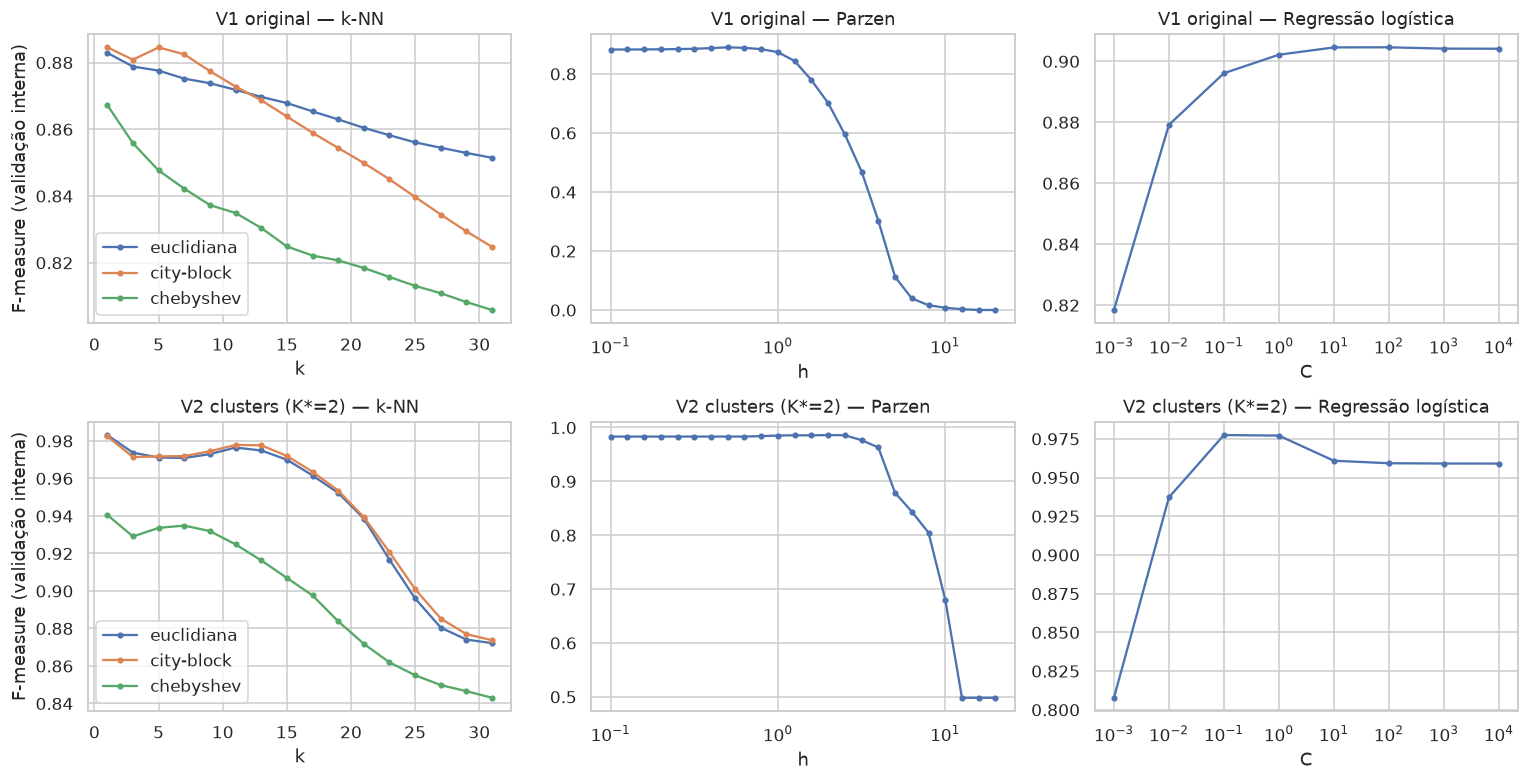

In [12]:
for nome in BASES:
    h = res_hp[res_hp.base == nome]
    print(f"===== {nome} =====")
    knn_freq = (h.metrica + ", k=" + h.k.astype(str)).value_counts()
    display(pd.DataFrame({"k-NN (distância, k)": knn_freq.index, "vezes": knn_freq.values}).head(8))
    display(h.h.value_counts().rename_axis("Parzen h").to_frame("vezes").head(8))
    display(h.C.value_counts().rename_axis("Reg. log. C").to_frame("vezes"))

fig, axs = plt.subplots(len(BASES), 3, figsize=(14, 3.6 * len(BASES)), squeeze=False)
for row, nome in enumerate(BASES):
    c = curvas_hp[nome]
    for mi, m in enumerate(METRICAS):
        axs[row, 0].plot(K_GRID, c["knn"][mi], "o-", ms=3, label=m)
    axs[row, 0].set(xlabel="k", ylabel="F-measure (validação interna)", title=f"{nome} — k-NN")
    axs[row, 0].legend()
    axs[row, 1].semilogx(H_GRID, c["parzen"], "o-", ms=3)
    axs[row, 1].set(xlabel="h", title=f"{nome} — Parzen")
    axs[row, 2].semilogx(C_GRID, c["lr"], "o-", ms=3)
    axs[row, 2].set(xlabel="C", title=f"{nome} — Regressão logística")
plt.tight_layout(); plt.savefig(f"{OUT}/q2_ajuste_hiperparametros.png", dpi=200); plt.show()

### 3.5 (b) Estimativas pontuais e intervalos de confiança

Para cada classificador, métrica e base: a média das 10 avaliações de cada repetição dá
30 valores (um por repetição). A **estimativa pontual** é a média desses 30 valores e o
**intervalo de confiança de 95%** é $\bar m\pm t_{0{,}975;\,29}\,s/\sqrt{30}$. Usamos as médias por
repetição, e não os 300 folds, porque os folds de uma mesma repetição compartilham dados de
treinamento e não são independentes.

In [13]:
METR = {"erro": "Taxa de erro", "precisao": "Precisão", "cobertura": "Cobertura", "f1": "F-measure"}
por_rep = res_cv.groupby(["base", "classificador", "rep"])[list(METR)].mean().reset_index()

def ic95(x):
    x = np.asarray(x); n = len(x); m = x.mean()
    meia = st.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    return m, m - meia, m + meia

linhas = []
for (base, clf), g in por_rep.groupby(["base", "classificador"], sort=False):
    for m in METR:
        mu, lo, hi = ic95(g[m])
        linhas.append(dict(base=base, classificador=clf, metrica=METR[m], media=mu, ic_inf=lo, ic_sup=hi,
                           dp_folds=res_cv[(res_cv.base == base) & (res_cv.classificador == clf)][m].std()))
tab_ic = pd.DataFrame(linhas)
tab_ic.to_csv(f"{OUT}/q2_estimativas_ic95.csv", index=False)
for base in BASES:
    t = tab_ic[tab_ic.base == base].copy()
    t["valor"] = t.apply(lambda r: f"{r.media:.4f} [{r.ic_inf:.4f}, {r.ic_sup:.4f}]", axis=1)
    print(f"===== {base}: média [IC 95%] =====")
    display(t.pivot(index="classificador", columns="metrica", values="valor")
             .reindex(index=NOMES_CLF, columns=list(METR.values())))

===== V1 original: média [IC 95%] =====


metrica,Taxa de erro,Precisão,Cobertura,F-measure
classificador,,,,
Gaussiano,"0.1767 [0.1763, 0.1770]","0.7052 [0.7048, 0.7057]","0.9499 [0.9494, 0.9504]","0.8092 [0.8089, 0.8096]"
k-NN,"0.0861 [0.0851, 0.0871]","0.9121 [0.9101, 0.9141]","0.8658 [0.8632, 0.8684]","0.8878 [0.8864, 0.8892]"
Parzen,"0.0792 [0.0786, 0.0798]","0.9138 [0.9129, 0.9147]","0.8826 [0.8812, 0.8840]","0.8977 [0.8969, 0.8985]"
Reg. logística,"0.0732 [0.0728, 0.0735]","0.9229 [0.9221, 0.9237]","0.8891 [0.8883, 0.8899]","0.9054 [0.9049, 0.9059]"
Voto majoritário,"0.0655 [0.0648, 0.0661]","0.9184 [0.9172, 0.9195]","0.9157 [0.9145, 0.9169]","0.9168 [0.9160, 0.9176]"


===== V2 clusters (K*=2): média [IC 95%] =====


metrica,Taxa de erro,Precisão,Cobertura,F-measure
classificador,,,,
Gaussiano,"0.0459 [0.0457, 0.0462]","0.5561 [0.5550, 0.5571]","0.8524 [0.8471, 0.8577]","0.5866 [0.5850, 0.5882]"
k-NN,"0.0008 [0.0007, 0.0008]","0.9812 [0.9785, 0.9838]","0.9720 [0.9695, 0.9746]","0.9726 [0.9709, 0.9743]"
Parzen,"0.0005 [0.0004, 0.0005]","0.9796 [0.9774, 0.9818]","0.9956 [0.9924, 0.9989]","0.9856 [0.9828, 0.9883]"
Reg. logística,"0.0007 [0.0006, 0.0008]","0.9680 [0.9646, 0.9714]","0.9955 [0.9922, 0.9988]","0.9789 [0.9759, 0.9818]"
Voto majoritário,"0.0004 [0.0003, 0.0005]","0.9807 [0.9782, 0.9832]","0.9973 [0.9945, 1.0002]","0.9872 [0.9846, 0.9898]"


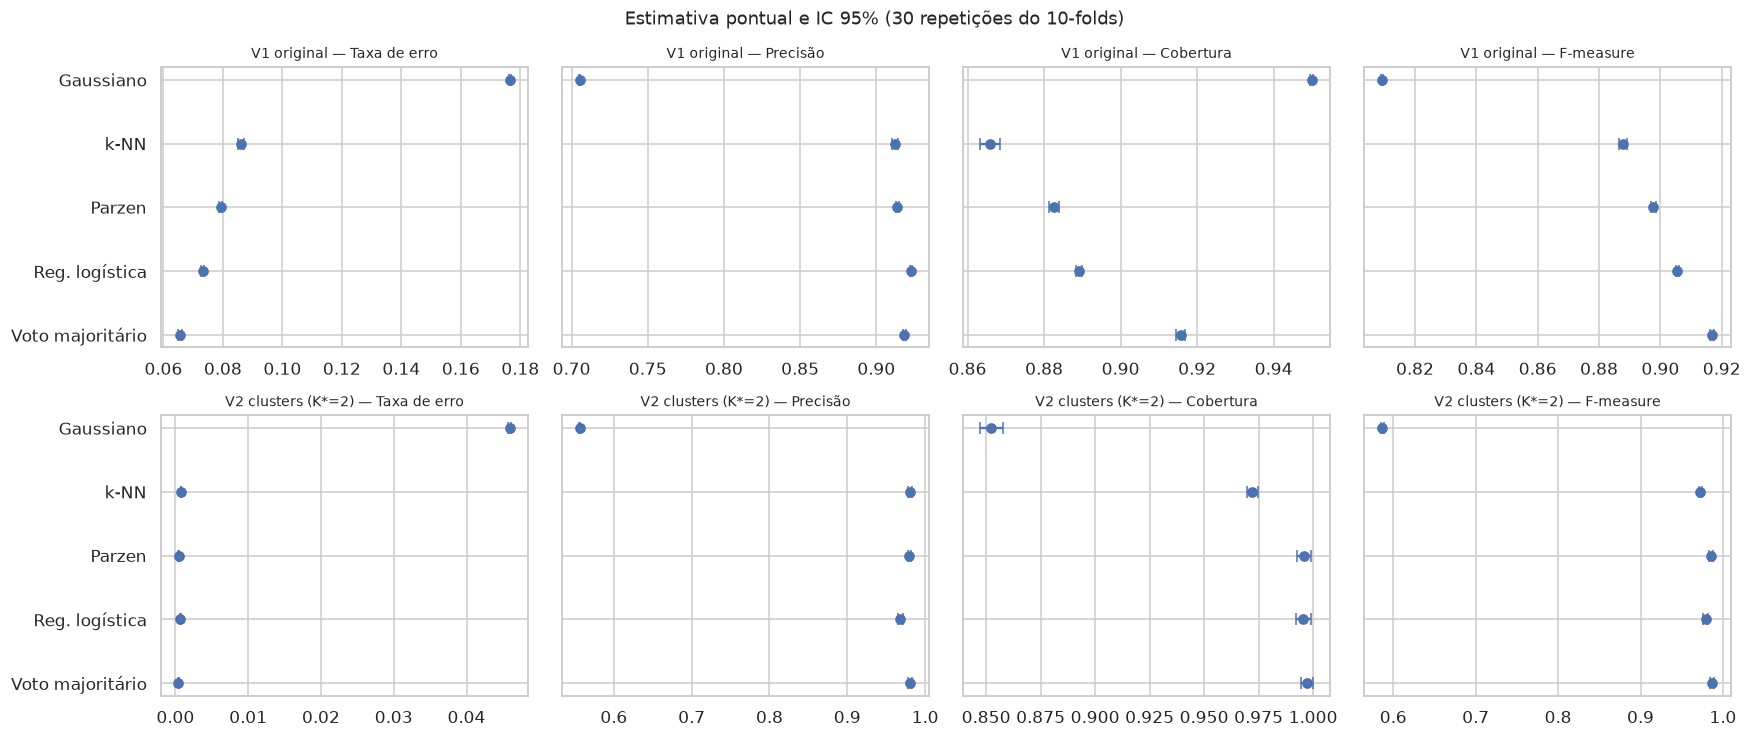

In [14]:
fig, axs = plt.subplots(len(BASES), 4, figsize=(16, 3.4 * len(BASES)), squeeze=False)
for row, base in enumerate(BASES):
    for col, m in enumerate(METR.values()):
        t = tab_ic[(tab_ic.base == base) & (tab_ic.metrica == m)].set_index("classificador").reindex(NOMES_CLF)
        ax = axs[row, col]
        ax.errorbar(t.media, range(len(t)), xerr=[t.media - t.ic_inf, t.ic_sup - t.media], fmt="o", capsize=4)
        ax.set_yticks(range(len(t))); ax.set_yticklabels(NOMES_CLF if col == 0 else [])
        ax.invert_yaxis(); ax.set_title(f"{base} — {m}", fontsize=9)
plt.suptitle("Estimativa pontual e IC 95% (30 repetições do 10-folds)")
plt.tight_layout(); plt.savefig(f"{OUT}/q2_ic95.png", dpi=200); plt.show()

### 3.6 (c) Teste de Friedman e pós-teste de Nemenyi

Para cada base e métrica, os blocos são as 30 repetições (média dos 10 folds) e os tratamentos
são os 5 classificadores. O **teste de Friedman** verifica se os postos médios dos classificadores
diferem ($H_0$: desempenhos equivalentes, $\alpha=0{,}05$). Se $H_0$ for rejeitada, o **pós-teste de
Nemenyi** compara os pares: dois classificadores diferem quando a diferença dos postos médios
passa da diferença crítica $CD=q_\alpha\sqrt{k(k+1)/(6N)}$ ($k=5$, $N=30$). O posto 1 é o melhor
(menor erro, ou maior precisão, cobertura ou F-measure).

In [15]:
k_clf, n_blocos = len(NOMES_CLF), por_rep.rep.nunique()
q_alpha = st.studentized_range.ppf(0.95, k_clf, np.inf) / np.sqrt(2)
CD = q_alpha * np.sqrt(k_clf * (k_clf + 1) / (6 * n_blocos))
print(f"Diferença crítica de Nemenyi (alfa = 0,05, k = {k_clf}, N = {n_blocos}): CD = {CD:.3f}")

linhas_fr, nemenyi = [], {}
for base in BASES:
    for m, rot in METR.items():
        M = (por_rep[por_rep.base == base].pivot(index="rep", columns="classificador", values=m)[NOMES_CLF])
        stat, p = st.friedmanchisquare(*[M[c].values for c in NOMES_CLF])
        postos = (M if m == "erro" else -M).rank(axis=1, method="average").mean()
        pv = sp.posthoc_nemenyi_friedman(M.values)
        pv.index = pv.columns = NOMES_CLF
        nemenyi[(base, rot)] = pv
        linhas_fr.append(dict(base=base, metrica=rot, chi2=stat, p_valor=p,
                              rejeita_H0=p < 0.05, **{f"posto {c}": postos[c] for c in NOMES_CLF}))
tab_fr = pd.DataFrame(linhas_fr)
tab_fr.to_csv(f"{OUT}/q2_friedman.csv", index=False)
display(tab_fr.round(4))

Diferença crítica de Nemenyi (alfa = 0,05, k = 5, N = 30): CD = 1.114


,base,metrica,chi2,p_valor,rejeita_H0,posto Gaussiano,posto k-NN,posto Parzen,posto Reg. logística,posto Voto majoritário
0,V1 original,Taxa de erro,120.0000,0.0,True,5.0,4.0000,3.0000,2.0000,1.0000
1,V1 original,Precisão,108.5067,0.0,True,5.0,3.5667,3.3333,1.1000,2.0000
2,V1 original,Cobertura,118.5067,0.0,True,1.0,5.0000,3.9333,3.0667,2.0000
3,V1 original,F-measure,120.0000,0.0,True,5.0,4.0000,3.0000,2.0000,1.0000
4,V2 clusters (K*=2),Taxa de erro,97.1022,0.0,True,5.0,3.4000,1.9000,3.1167,1.5833
5,V2 clusters (K*=2),Precisão,94.0353,0.0,True,5.0,2.7500,1.9167,3.6500,1.6833
6,V2 clusters (K*=2),Cobertura,98.1773,0.0,True,5.0,3.7500,1.9667,2.6833,1.6000
7,V2 clusters (K*=2),F-measure,98.2584,0.0,True,5.0,3.6000,1.8833,2.9667,1.5500


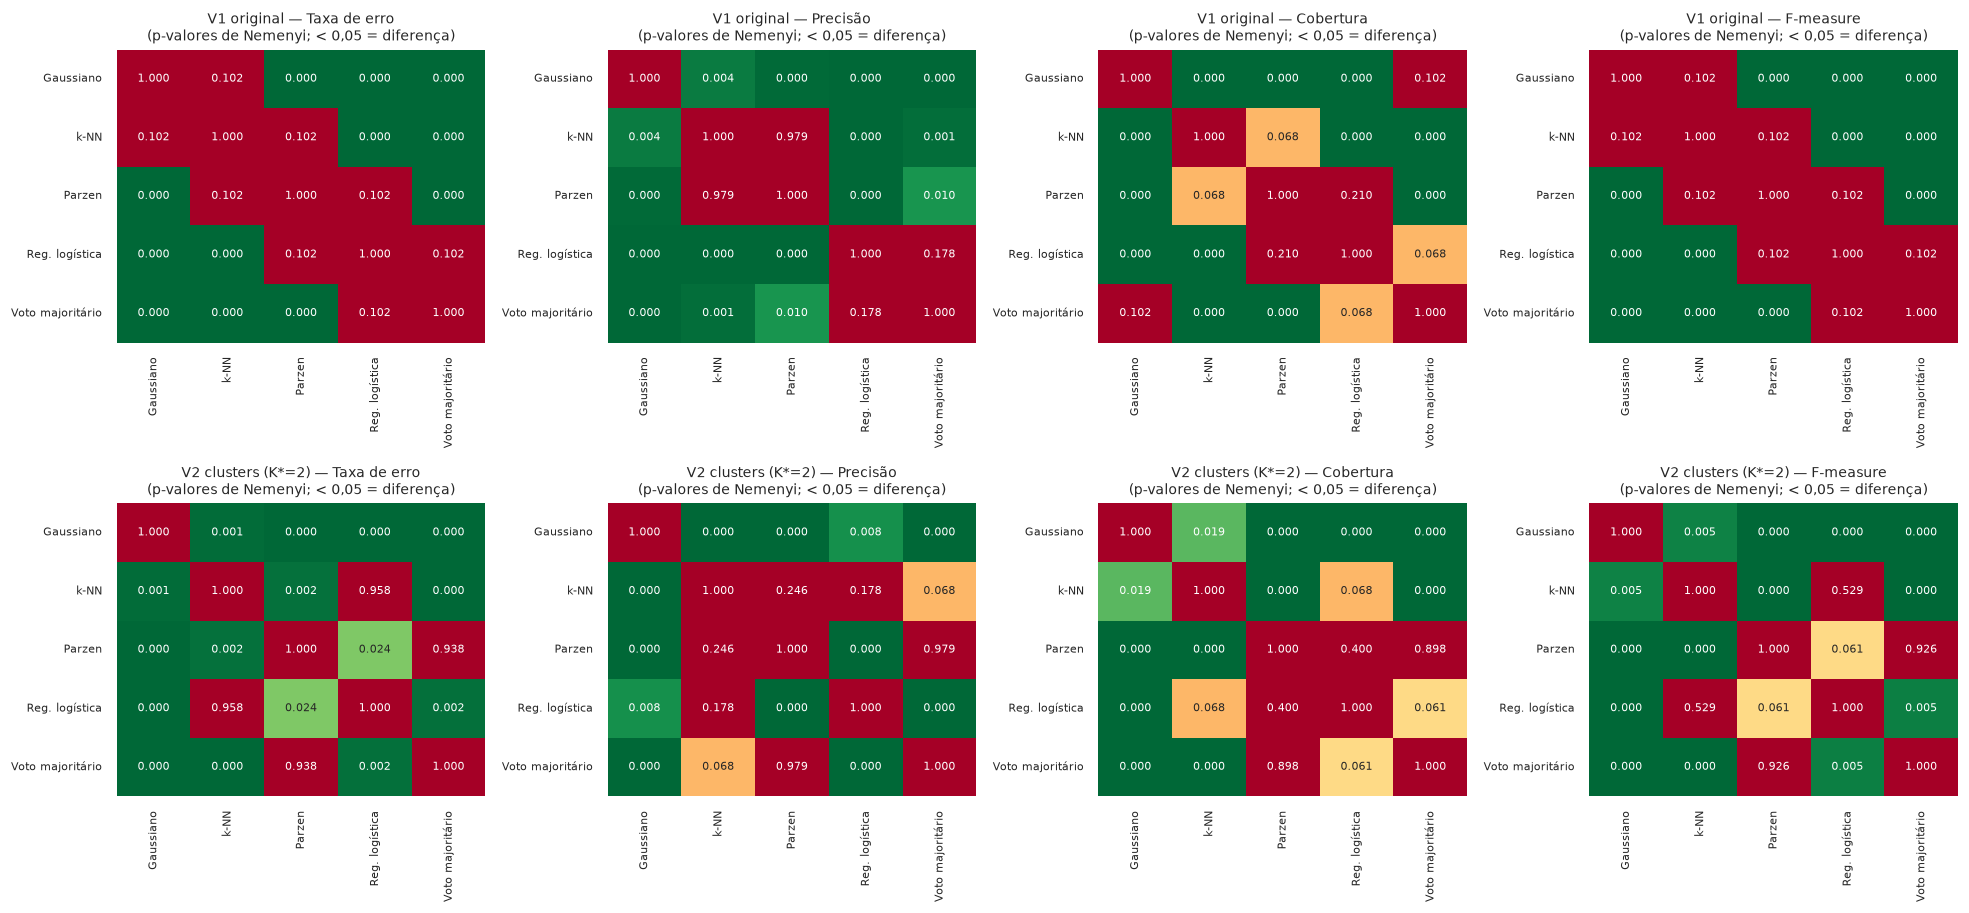

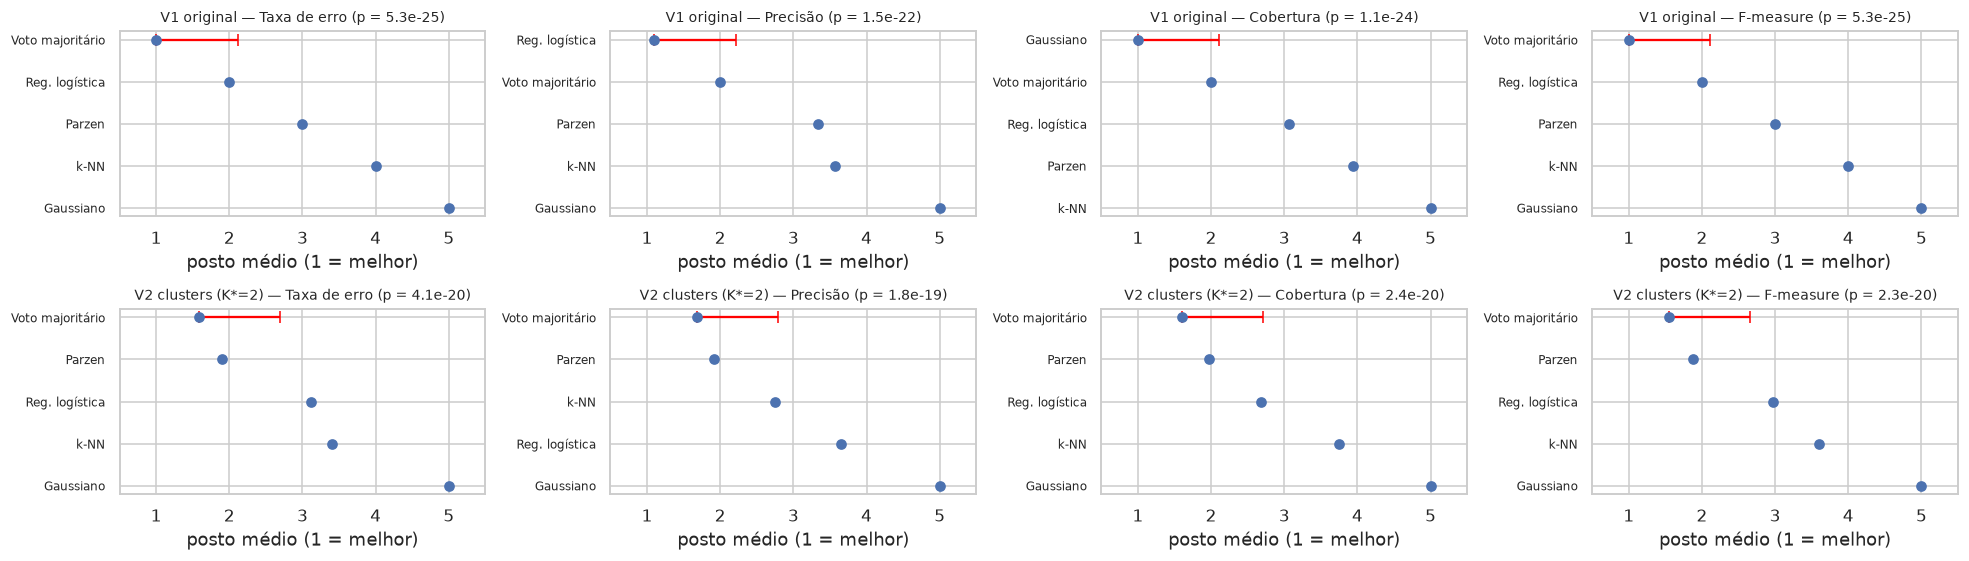

In [16]:
fig, axs = plt.subplots(len(BASES), 4, figsize=(18, 4.2 * len(BASES)), squeeze=False)
for row, base in enumerate(BASES):
    for col, rot in enumerate(METR.values()):
        pv = nemenyi[(base, rot)]
        sns.heatmap(pv, annot=True, fmt=".3f", cmap="RdYlGn_r", vmin=0, vmax=0.1, cbar=False,
                    ax=axs[row, col], annot_kws={"size": 7})
        axs[row, col].set_title(f"{base} — {rot}\n(p-valores de Nemenyi; < 0,05 = diferença)", fontsize=9)
        axs[row, col].tick_params(labelsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/q2_nemenyi.png", dpi=200); plt.show()

pd.concat({f"{b} | {m}": pv for (b, m), pv in nemenyi.items()}).to_csv(f"{OUT}/q2_nemenyi_pvalores.csv")

# postos médios com a diferença crítica
fig, axs = plt.subplots(len(BASES), 4, figsize=(18, 2.6 * len(BASES)), squeeze=False)
for row, base in enumerate(BASES):
    for col, rot in enumerate(METR.values()):
        r = tab_fr[(tab_fr.base == base) & (tab_fr.metrica == rot)].iloc[0]
        postos = pd.Series({c: r[f"posto {c}"] for c in NOMES_CLF}).sort_values()
        ax = axs[row, col]
        ax.scatter(postos.values, range(len(postos)), zorder=3)
        ax.set_yticks(range(len(postos))); ax.set_yticklabels(postos.index, fontsize=8)
        ax.errorbar(postos.values[0], 0, xerr=[[0], [CD]], fmt="none", ecolor="red", capsize=4, label="CD")
        ax.set_xlim(0.5, k_clf + 0.5); ax.invert_yaxis()
        ax.set_title(f"{base} — {rot} (p = {r.p_valor:.2g})", fontsize=9)
        ax.set_xlabel("posto médio (1 = melhor)")
plt.tight_layout(); plt.savefig(f"{OUT}/q2_postos_medios.png", dpi=200); plt.show()

### 3.7 (d) Curvas de aprendizagem

Para cada proporção de treinamento de 5% a 95% (passo de 5%), a base é dividida em treino e teste
por **amostragem estratificada**. Os 5 classificadores usam os hiper-parâmetros **mais escolhidos**
na validação cruzada da seção 3.4. As métricas são calculadas no treino e no teste. Cada
proporção é repetida 5 vezes com sementes diferentes, e a curva mostra a média.

In [17]:
PROPS = np.round(np.arange(0.05, 0.951, 0.05), 2)
N_LC = 2 if QUICK else 5
linhas = []
t0 = time.time()
for nome, b in BASES.items():
    h = res_hp[res_hp.base == nome]
    hp_modal = dict(metrica=(h.metrica + "|" + h.k.astype(str)).mode()[0].split("|")[0],
                    k=int((h.metrica + "|" + h.k.astype(str)).mode()[0].split("|")[1]),
                    h=float(h.h.mode()[0]), C=float(h.C.mode()[0]))
    print(nome, "-> hiper-parâmetros usados na curva:", hp_modal)
    y = b["y"]
    for prop in PROPS:
        for s in range(N_LC):
            try:
                tr, te = train_test_split(np.arange(N), train_size=float(prop), stratify=y, random_state=SEED + s)
            except ValueError as e:
                print("  pulando", prop, s, e); continue
            p_tr = treina_e_preve(X_raw[tr], y[tr], X_raw[tr], b["C"], hp_modal)
            p_te = treina_e_preve(X_raw[tr], y[tr], X_raw[te], b["C"], hp_modal)
            for clf in NOMES_CLF:
                for conj, idx, p in (("treino", tr, p_tr), ("teste", te, p_te)):
                    linhas.append(dict(base=nome, prop_treino=prop, seed=s, classificador=clf, conjunto=conj,
                                       **metricas(y[idx], p[clf].argmax(1).cpu().numpy(), b["media"])))
print("Curvas de aprendizagem: %.1f s" % (time.time() - t0))
res_lc = pd.DataFrame(linhas)
res_lc.to_csv(f"{OUT}/q2_curva_aprendizagem.csv", index=False)

V1 original -> hiper-parâmetros usados na curva: {'metrica': 'city-block', 'k': 1, 'h': 0.5015, 'C': 10.0}


V2 clusters (K*=2) -> hiper-parâmetros usados na curva: {'metrica': 'euclidiana', 'k': 1, 'h': 0.1, 'C': 0.1}


Curvas de aprendizagem: 86.6 s


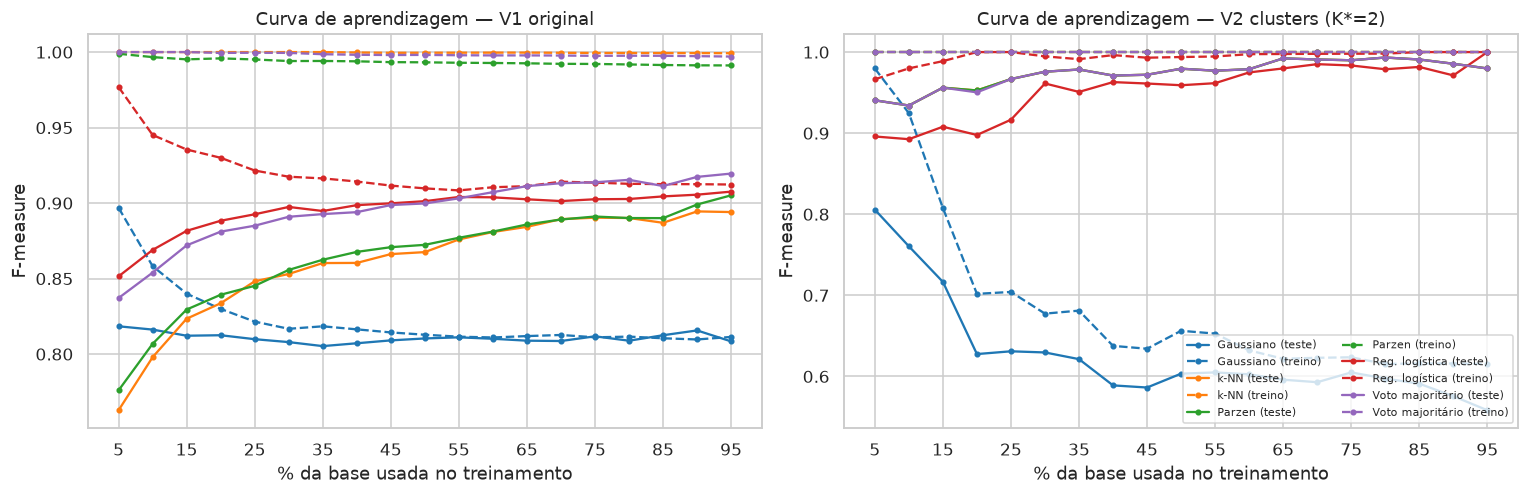

prop_treino                                     0.05    0.25    0.50    0.75  \
base               classificador    conjunto                                   
V1 original        Gaussiano        teste     0.8184  0.8098  0.8103  0.8117   
                                    treino    0.8969  0.8215  0.8128  0.8111   
                   Parzen           teste     0.7760  0.8452  0.8723  0.8911   
                                    treino    0.9989  0.9951  0.9932  0.9921   
                   Reg. logística   teste     0.8515  0.8926  0.9013  0.9025   
                                    treino    0.9768  0.9216  0.9097  0.9135   
                   Voto majoritário teste     0.8371  0.8850  0.8998  0.9137   
                                    treino    1.0000  0.9996  0.9981  0.9975   
                   k-NN             teste     0.7628  0.8482  0.8675  0.8903   
                                    treino    1.0000  1.0000  0.9996  0.9994   
V2 clusters (K*=2) Gaussiano        teste     0.8057  0.6309  0.6034  0.6049   
                                    treino    0.9798  0.7042  0.6562  0.6236   
                   Parzen           teste     0.9405  0.9667  0.9795  0.9899   
                                    treino    1.0000  1.0000  1.0000  1.0000   
                   Reg. logística   teste     0.8959  0.9166  0.9591  0.9835   
                                    treino    0.9664  1.0000  0.9939  0.9979   
                   Voto majoritário teste     0.9405  0.9667  0.9795  0.9899   
                                    treino    1.0000  1.0000  1.0000  1.0000   
                   k-NN             teste     0.9405  0.9667  0.9795  0.9899   
                                    treino    1.0000  1.0000  1.0000  1.0000   

prop_treino                                     0.95  
base               classificador    conjunto          
V1 original        Gaussiano        teste     0.8084  
                                    treino    0.8113  
                   Parzen           teste     0.9051  
                                    treino    0.9912  
                   Reg. logística   teste     0.9076  
                                    treino    0.9123  
                   Voto majoritário teste     0.9195  
                                    treino    0.9970  
                   k-NN             teste     0.8940  
                                    treino    0.9992  
V2 clusters (K*=2) Gaussiano        teste     0.5582  
                                    treino    0.6154  
                   Parzen           teste     0.9798  
                                    treino    1.0000  
                   Reg. logística   teste     1.0000  
                                    treino    1.0000  
                   Voto majoritário teste     0.9798  
                                    treino    1.0000  
                   k-NN             teste     0.9798  
                                    treino    1.0000

In [18]:
cores_clf = dict(zip(NOMES_CLF, sns.color_palette("tab10", len(NOMES_CLF))))
lc = res_lc.groupby(["base", "classificador", "conjunto", "prop_treino"])[list(METR)].mean().reset_index()
fig, axs = plt.subplots(1, len(BASES), figsize=(7 * len(BASES), 4.6), squeeze=False)
for col, base in enumerate(BASES):
    ax = axs[0, col]
    for clf in NOMES_CLF:
        for conj, ls in (("teste", "-"), ("treino", "--")):
            g = lc[(lc.base == base) & (lc.classificador == clf) & (lc.conjunto == conj)]
            ax.plot(100 * g.prop_treino, g.f1, ls, color=cores_clf[clf], marker="o", ms=3,
                    label=f"{clf} ({conj})")
    ax.set(xlabel="% da base usada no treinamento", ylabel="F-measure", title=f"Curva de aprendizagem — {base}")
    ax.set_xticks(range(5, 100, 10))
axs[0, -1].legend(fontsize=7, ncol=2, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/q2_curva_aprendizagem_f1.png", dpi=200); plt.show()

display(lc[lc.prop_treino.isin([0.05, 0.25, 0.5, 0.75, 0.95])]
        .pivot_table(index=["base", "classificador", "conjunto"], columns="prop_treino", values="f1").round(4))

### Comentários — Questão 2

**V1 (classe original).**
* O **voto majoritário** é o melhor em taxa de erro (**6,55%**, IC 95% [6,48; 6,61]) e em
  F-measure (**0,917**). Depois vêm regressão logística (7,32%; F = 0,905), Parzen (7,92%;
  F = 0,898), k-NN (8,61%; F = 0,888) e, por último, o bayesiano gaussiano (17,67%; F = 0,809).
* O gaussiano tem a **maior cobertura (0,950)**, mas **precisão baixa (0,705)**: classifica muitos
  e-mails legítimos como spam. A hipótese de normalidade é ruim para atributos esparsos (maioria
  de zeros) e de cauda pesada.
* **Friedman** rejeita $H_0$ em todas as métricas ($p<10^{-20}$). Em erro e F-measure a ordem é a
  mesma nas 30 repetições (postos 1 a 5). Com **CD = 1,114**, o **Nemenyi** não separa
  classificadores vizinhos na ordem (diferença de posto = 1; $p=0{,}10$), mas separa todos os pares
  com dois ou mais postos de distância ($p<0{,}001$). Por exemplo, voto majoritário > Parzen,
  k-NN e gaussiano, e regressão logística > k-NN e gaussiano.
* **Hiper-parâmetros:** k-NN com $k$ pequeno ($k=1$ a 7), em geral City-Block; Parzen com
  $h\approx0{,}5$; regressão logística com $C$ entre 10 e 100 (pouca regularização).

**V2 (classe = clusters de $K^*=2$).**
* A base fica extremamente desbalanceada (4567 × 34). A tarefa é fácil porque as classes foram
  definidas pelo próprio agrupamento, a partir de um grupo extremo em poucas variáveis. Erros:
  voto 0,04%, Parzen 0,05%, regressão logística 0,07%, k-NN 0,08%. F-measure macro: voto 0,987,
  Parzen 0,986, regressão logística 0,979, k-NN 0,973.
* O gaussiano é bem pior (erro 4,6%, F-measure 0,587): estimar uma covariância 57×57 com ~31
  exemplos de treino da classe minoritária é mal condicionado, mesmo com regularização.
* Friedman rejeita $H_0$ em todas as métricas. No Nemenyi (F-measure), voto e Parzen não diferem
  ($p=0{,}93$) e ambos superam k-NN, gaussiano e (o voto) a regressão logística. Regressão
  logística e k-NN não diferem ($p=0{,}53$).
* O $h$ de Parzen mais escolhido na V2 foi o menor da grade (0,1). Com uma grade mais fina abaixo
  de 0,1 o resultado poderia mudar pouco, já que o erro já está próximo de zero.

**Curvas de aprendizagem (F-measure).**
* **V1:** k-NN e Parzen têm F-measure de treino ≈ 1 (com $k=1$ e $h$ pequeno eles memorizam o
  treino), e a de teste cresce com o tamanho do treino (0,76 → 0,89 e 0,78 → 0,91): **alta
  variância**, que diminui com mais dados. A regressão logística fica próxima no treino e no teste
  (≈ 0,91 a partir de 25%): baixa variância. O gaussiano fica estável em ≈ 0,81 no treino e no
  teste: **alto viés**, mais dados não ajudam. O voto majoritário é o melhor em teste a partir de
  ~50% (0,920 com 95%).
* **V2:** k-NN, Parzen e voto têm curvas praticamente iguais (0,94 → 0,98). A regressão logística
  chega a 1,0 com 95% de treino. O gaussiano piora com mais treino (0,81 → 0,56), coerente com a
  dificuldade de modelar a classe minoritária com uma normal multivariada.

**Observação.** Os intervalos de confiança são estreitos porque cada um vem da média de 30
repetições do 10-folds sobre a mesma base. Eles medem a variabilidade da partição em folds, não
a de amostrar novos conjuntos de dados.


In [19]:
print("Tempo total do notebook: %.1f min" % ((time.time() - T0_GLOBAL) / 60))
print("Arquivos gerados em", OUT, ":", sorted(os.listdir(OUT)))

Tempo total do notebook: 42.6 min
Arquivos gerados em resultados_versao_final : ['q1_matriz_G.png', 'q1_matriz_confusao.png', 'q1_objetivo_iteracoes.png', 'q1_pares_KH.csv', 'q1_resumo.json', 'q1_silhueta.png', 'q2_ajuste_hiperparametros.png', 'q2_curva_aprendizagem.csv', 'q2_curva_aprendizagem_f1.png', 'q2_cv_por_fold.csv', 'q2_estimativas_ic95.csv', 'q2_friedman.csv', 'q2_hiperparametros_por_fold.csv', 'q2_ic95.png', 'q2_nemenyi.png', 'q2_nemenyi_pvalores.csv', 'q2_postos_medios.png']
